In [1]:
import os                       # work with file paths
from pathlib import Path         # path handling
import pandas as pd              # main data tool 
import numpy as np               # numerical helpers

# plotting
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (12,6)  # default plot size
# show plots inline
%matplotlib inline                     

# ML basics
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# time-series
from prophet import Prophet
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose  # seasonal decomposition for seasonal analysis visualization

# saving models
import joblib

# explainability 
import shap

# warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings for Jupyter
pd.set_option('display.max_columns', 200)
sns.set_style('whitegrid')

In [2]:
# csv data filename
DATA_FILENAME = 'sales_dataset.csv'

# Project root 
ROOT = Path.cwd().parent

# Dataset path
DATA_DIR = ROOT / 'data'
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / DATA_FILENAME

# Models directory inside ROOT
MODELS_DIR = ROOT / 'models'
MODELS_DIR.mkdir(exist_ok=True)

# Display paths
print("ROOT:", ROOT)
print("DATA_PATH:", DATA_PATH)
print("MODELS_DIR:", MODELS_DIR.resolve())

ROOT: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail
DATA_PATH: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\sales_dataset.csv
MODELS_DIR: C:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\models


In [3]:
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    print(f"CSV loaded successfully from: {DATA_PATH}")
    print("Shape:", df.shape)
except FileNotFoundError:
    print(f"File not found at: {DATA_PATH}")
except Exception as e:
    print("Error loading CSV:", e)

CSV loaded successfully from: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\sales_dataset.csv
Shape: (9994, 11)


In [4]:
# Convert Order Date to Date Format
date_cols = [col for col in df.columns if "date" in col.lower()]

for col in date_cols:
    df[col + "_raw"] = df[col].astype(str)   # backup original
    df[col] = pd.to_datetime(df[col], format='mixed', dayfirst=True, errors='coerce')
df.head()

,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State,Order Date_raw
0,OD1,Harish,Oil & Masala,Masalas,Vellore,2017-08-11,North,1254,0.12,401.28,Tamil Nadu,11-08-2017
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,2017-08-11,South,749,0.18,149.80,Tamil Nadu,11-08-2017
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,2017-12-06,West,2360,0.21,165.20,Tamil Nadu,06-12-2017
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,2016-11-10,South,896,0.25,89.60,Tamil Nadu,10-11-2016
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,2016-11-10,South,2355,0.26,918.45,Tamil Nadu,10-11-2016


In [5]:
print("DATA EXPLORATION\n")

# Columns & first rows
print("Columns:", df.columns.tolist())
display(df.head())

# Dataset info (dtypes + non-null counts)
print("\nDataFrame Info:")
df.info()

# Summary Stats
print("\nSummary Statistics (Numeric):")
display(df.describe().T)

# Missing values
print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

DATA EXPLORATION

Columns: ['Order ID', 'Customer Name', 'Category', 'Sub Category', 'City', 'Order Date', 'Region', 'Sales', 'Discount', 'Profit', 'State', 'Order Date_raw']


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State,Order Date_raw
0,OD1,Harish,Oil & Masala,Masalas,Vellore,2017-08-11,North,1254,0.12,401.28,Tamil Nadu,11-08-2017
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,2017-08-11,South,749,0.18,149.80,Tamil Nadu,11-08-2017
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,2017-12-06,West,2360,0.21,165.20,Tamil Nadu,06-12-2017
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,2016-11-10,South,896,0.25,89.60,Tamil Nadu,10-11-2016
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,2016-11-10,South,2355,0.26,918.45,Tamil Nadu,10-11-2016



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   object        
 1   Customer Name   9994 non-null   object        
 2   Category        9994 non-null   object        
 3   Sub Category    9994 non-null   object        
 4   City            9994 non-null   object        
 5   Order Date      9994 non-null   datetime64[ns]
 6   Region          9994 non-null   object        
 7   Sales           9994 non-null   int64         
 8   Discount        9994 non-null   float64       
 9   Profit          9994 non-null   float64       
 10  State           9994 non-null   object        
 11  Order Date_raw  9994 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(8)
memory usage: 937.1+ KB

Summary Statistics (Numeric):


,count,mean,min,25%,50%,75%,max,std
Order Date,9994,2017-04-11 12:33:42.973784064,2015-01-02 00:00:00,2016-05-01 00:00:00,2017-05-30 00:00:00,2018-04-09 00:00:00,2018-12-30 00:00:00,NaN
Sales,9994.0,1496.596158,500.0,1000.0,1498.0,1994.75,2500.0,577.559036
Discount,9994.0,0.226817,0.1,0.16,0.23,0.29,0.35,0.074636
Profit,9994.0,374.937082,25.25,180.0225,320.78,525.6275,1120.95,239.932881



Missing values per column:


Order ID          0
Customer Name     0
Category          0
Sub Category      0
City              0
Order Date        0
Region            0
Sales             0
Discount          0
Profit            0
State             0
Order Date_raw    0
dtype: int64


Duplicate rows: 0


In [6]:
"""
    Cleans dataset by:
    - Removing duplicate rows
    - Filling missing numeric values with mean
    - Filling missing categorical values with mode
"""

def clean_dataset(df):

    # Remove rows where all values are NaN
    df = df.dropna(how='all').copy()
    
    # Remove duplicates
    df = df.drop_duplicates().copy()

    # Handle numeric columns (mean)
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    for col in numeric_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mean())

    # Handle categorical columns (mode)
    categorical_cols = df.select_dtypes(include='object').columns
    for col in categorical_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mode()[0])

    return df

df = clean_dataset(df)
df.isnull().sum()

Order ID          0
Customer Name     0
Category          0
Sub Category      0
City              0
Order Date        0
Region            0
Sales             0
Discount          0
Profit            0
State             0
Order Date_raw    0
dtype: int64

In [7]:
# Saving cleaned dataset
cleaned_path = DATA_DIR / "cleaned_data.csv"
df.to_csv(cleaned_path, index=False)
print("Cleaned dataset saved to:", cleaned_path)

Cleaned dataset saved to: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\cleaned_data.csv


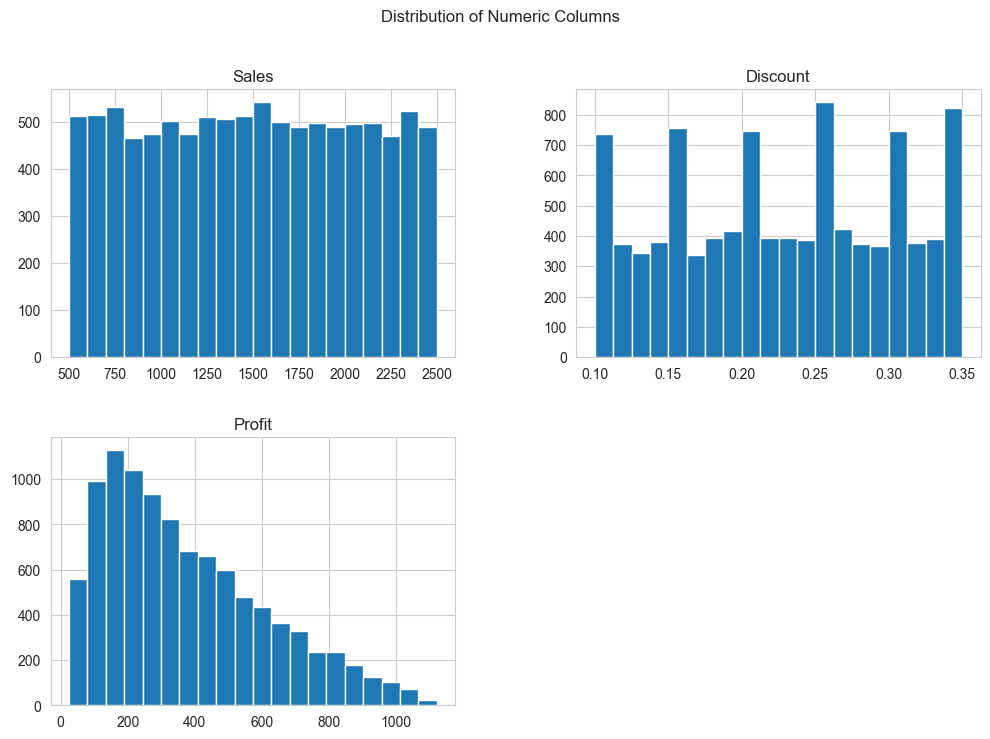

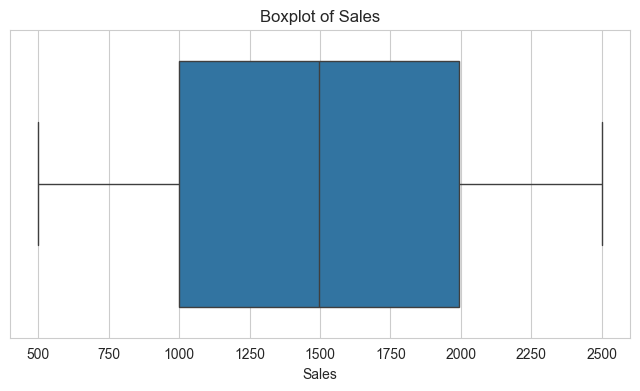

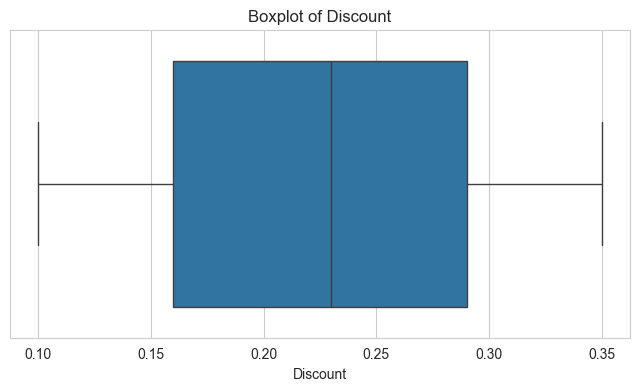

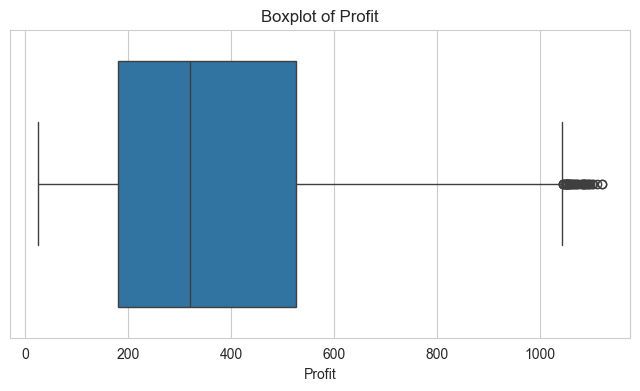

In [8]:
# Histograms for numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_cols].hist(bins=20, figsize=(12,8))
plt.suptitle("Distribution of Numeric Columns")
plt.show()

# Boxplots for outliers
for col in numeric_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

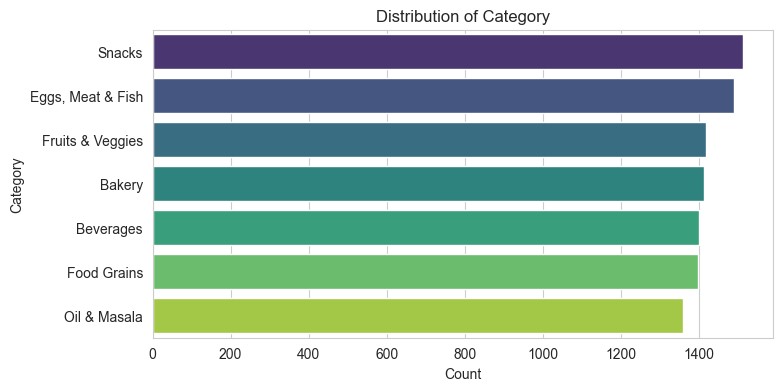

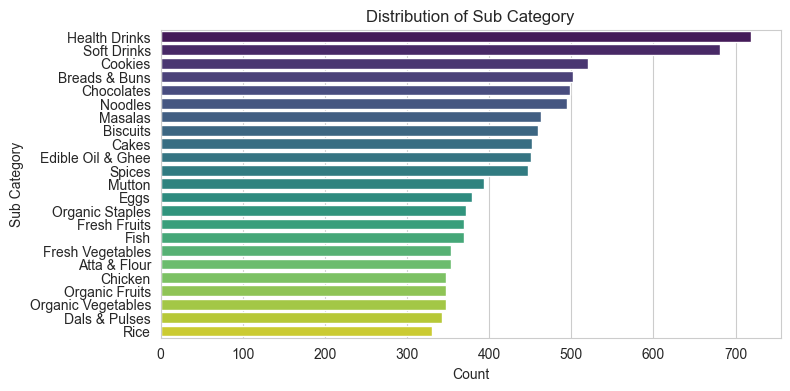

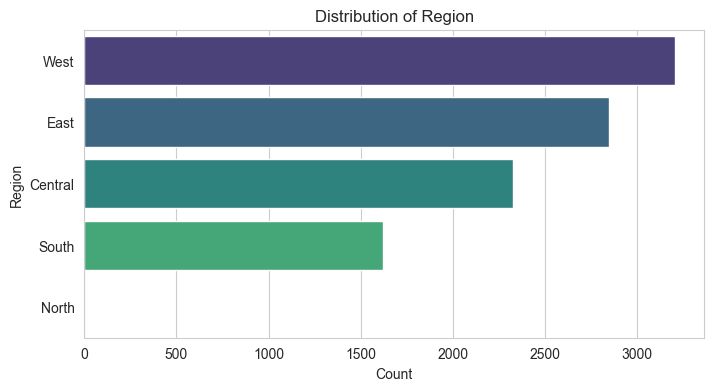

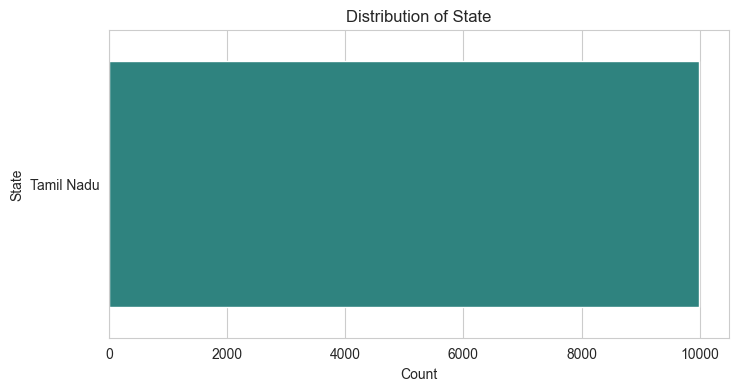

In [9]:
# Key categorical columns to visualize
key_categorical_cols = ['Category', 'Sub Category', 'Region', 'State']

for col in key_categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(8,4))
        sns.countplot(y=df[col], order=df[col].value_counts().index, palette="viridis")
        plt.title(f"Distribution of {col}")
        plt.xlabel("Count")
        plt.ylabel(col)
        plt.show()

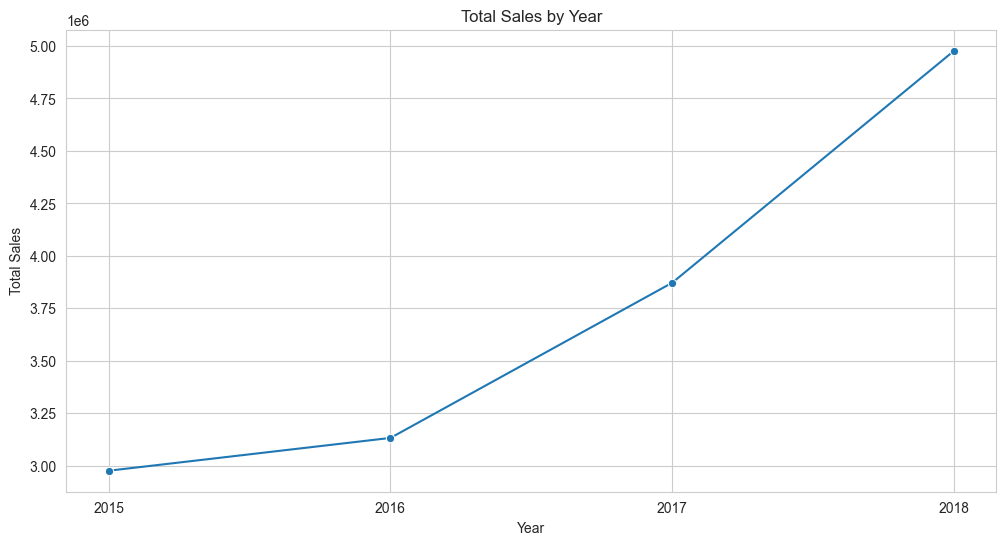

In [10]:
# Convert Year to integer
df['Year'] = df['Order Date'].dt.year.astype(int)

# Aggregate sales
sales_trend = df.groupby('Year')['Sales'].sum().reset_index()

# Plot
sns.lineplot(data=sales_trend, x='Year', y='Sales', marker='o')
plt.title("Total Sales by Year")
plt.ylabel("Total Sales")
plt.xlabel("Year")

plt.xticks(sales_trend['Year'])
plt.show()

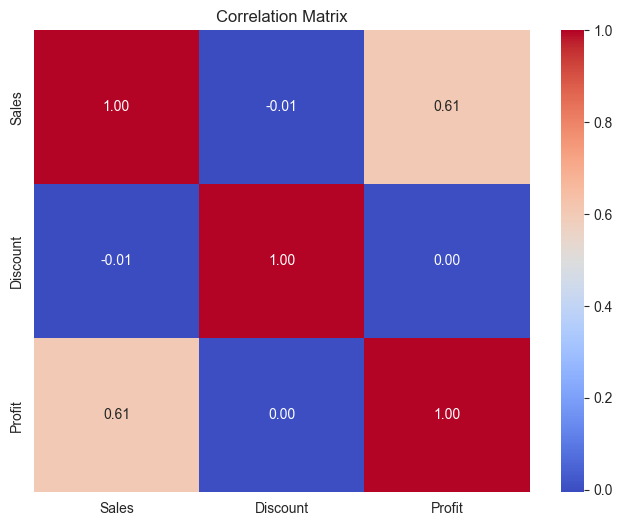

In [11]:
# Correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [12]:
# Feature Engineering: Date features
df['Month'] = df['Order Date'].dt.month
df['Day'] = df['Order Date'].dt.day
df['WeekOfYear'] = df['Order Date'].dt.isocalendar().week
df['DayOfWeek'] = df['Order Date'].dt.dayofweek
df['Is_Weekend'] = df['DayOfWeek'].isin([5,6]).astype(int)
df['DayOfYear'] = df['Order Date'].dt.dayofyear
df['Quarter'] = df['Order Date'].dt.quarter
df['Month_Year'] = df['Order Date'].dt.to_period('M').astype(str)

In [13]:
# Numeric features
df['Discount_Impact'] = df['Sales'] * df['Discount']
df['Profit_Margin'] = df['Profit'] / df['Sales']
df['Log_Sales'] = np.log1p(df['Sales'])
df['Sales_per_Discount'] = df['Sales'] / (df['Discount'] + 1e-9)
df['Profit_per_Sale'] = df['Profit'] / (df['Sales'] + 1e-9)
df.head()

,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State,Order Date_raw,Year,Month,Day,WeekOfYear,DayOfWeek,Is_Weekend,DayOfYear,Quarter,Month_Year,Discount_Impact,Profit_Margin,Log_Sales,Sales_per_Discount,Profit_per_Sale
0,OD1,Harish,Oil & Masala,Masalas,Vellore,2017-08-11,North,1254,0.12,401.28,Tamil Nadu,11-08-2017,2017,8,11,32,4,0,223,3,2017-08,150.48,0.32,7.134891,10449.999913,0.32
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,2017-08-11,South,749,0.18,149.80,Tamil Nadu,11-08-2017,2017,8,11,32,4,0,223,3,2017-08,134.82,0.20,6.620073,4161.111088,0.20
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,2017-12-06,West,2360,0.21,165.20,Tamil Nadu,06-12-2017,2017,12,6,49,2,0,340,4,2017-12,495.60,0.07,7.766841,11238.095185,0.07
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,2016-11-10,South,896,0.25,89.60,Tamil Nadu,10-11-2016,2016,11,10,45,3,0,315,4,2016-11,224.00,0.10,6.799056,3583.999986,0.10
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,2016-11-10,South,2355,0.26,918.45,Tamil Nadu,10-11-2016,2016,11,10,45,3,0,315,4,2016-11,612.30,0.39,7.764721,9057.692273,0.39


In [14]:
# Holiday Features
df['Is_December'] = (df['Month'] == 12).astype(int)
df['Is_Festive_Season'] = df['Month'].isin([11,12,1]).astype(int)

In [15]:
# Categorical encoding 
cat_cols = ['Category', 'Sub Category', 'Region', 'State']
cat_cols = [c for c in cat_cols if c in df.columns]

if len(cat_cols):
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("Categorical columns encoded:", cat_cols)

Categorical columns encoded: ['Category', 'Sub Category', 'Region', 'State']


In [16]:
# Saving feature-engineered dataset
featured_path = DATA_DIR / "featured_data.csv"
df.to_csv(featured_path, index=False)
print("Feature-engineered dataset saved to:", featured_path)

Feature-engineered dataset saved to: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\featured_data.csv


In [17]:
# aggregate time series (daily & monthly)
daily_ts = df.groupby('Order Date')['Sales'].sum().rename('Sales').to_frame()
monthly_ts = df.groupby(pd.Grouper(key='Order Date', freq='M'))['Sales'].sum().rename('Sales').to_frame()

print("Daily series length:", len(daily_ts))
display(daily_ts.head())
display(monthly_ts.head())

Daily series length: 1236


,Sales
Order Date,
2015-01-02,1338
2015-01-03,15163
2015-01-04,6580
2015-01-06,16101
2015-01-07,5431


,Sales
Order Date,
2015-01-31,203014
2015-02-28,120444
2015-03-31,260072
2015-04-30,176187
2015-05-31,218740


In [18]:
# Saving daily time-series dataset
daily_ts_path = DATA_DIR / "daily_ts.csv"
daily_ts.to_csv(daily_ts_path, index=False)
print("Daily dataset saved to:", daily_ts_path)

Daily dataset saved to: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\daily_ts.csv


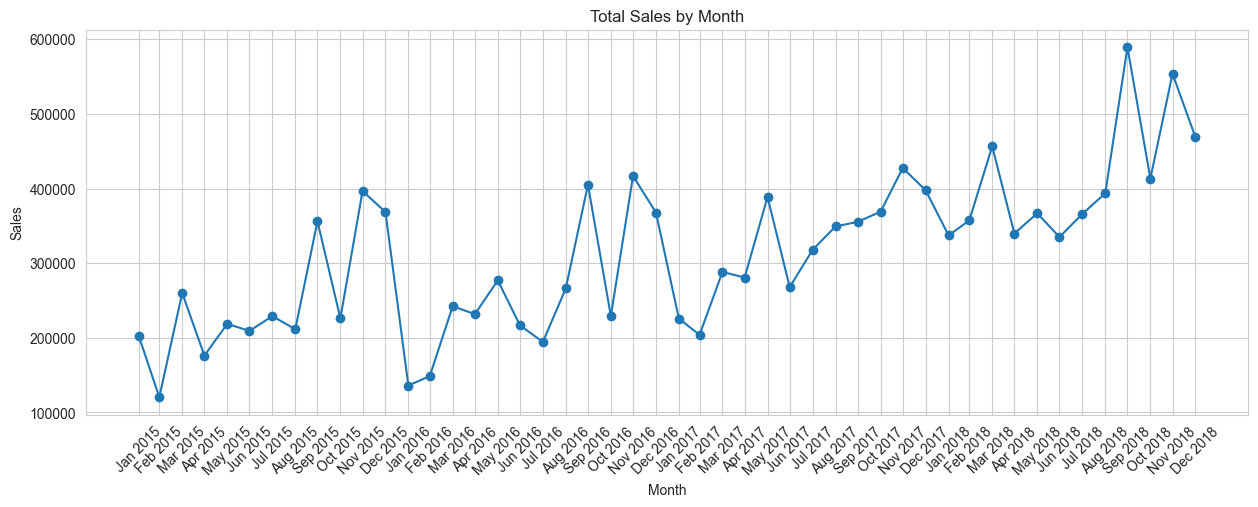

In [19]:
# plotting monthly sales
plt.figure(figsize=(15,5))
plt.plot(monthly_ts.index, monthly_ts['Sales'], marker='o')
plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(ticks=monthly_ts.index, labels=monthly_ts.index.strftime('%b %Y'), rotation=45)
plt.grid(True)
plt.show()

In [20]:
# monthly feature dataset for regression
monthly = df.copy()
monthly['MonthStart'] = monthly['Order Date'].dt.to_period('M').dt.to_timestamp()
monthly_agg = monthly.groupby('MonthStart').agg({
    'Sales':'sum',
    'Profit':'sum',
    'Discount':'mean'
}).reset_index().rename(columns={'MonthStart':'ds'})
monthly_agg.head()

,ds,Sales,Profit,Discount
0,2015-01-01,203014,54689.18,0.228321
1,2015-02-01,120444,32737.87,0.231628
2,2015-03-01,260072,66217.50,0.216131
3,2015-04-01,176187,46030.20,0.226446
4,2015-05-01,218740,50899.84,0.232838


In [21]:
# Time-based features
monthly_agg['year'] = monthly_agg['ds'].dt.year
monthly_agg['month'] = monthly_agg['ds'].dt.month
monthly_agg['quarter'] = monthly_agg['ds'].dt.quarter

monthly_agg.head()

,ds,Sales,Profit,Discount,year,month,quarter
0,2015-01-01,203014,54689.18,0.228321,2015,1,1
1,2015-02-01,120444,32737.87,0.231628,2015,2,1
2,2015-03-01,260072,66217.50,0.216131,2015,3,1
3,2015-04-01,176187,46030.20,0.226446,2015,4,2
4,2015-05-01,218740,50899.84,0.232838,2015,5,2


In [22]:
# Lag features
monthly_agg['lag_1'] = monthly_agg['Sales'].shift(1)
monthly_agg['lag_2'] = monthly_agg['Sales'].shift(2)
monthly_agg['lag_3'] = monthly_agg['Sales'].shift(3)
monthly_agg['lag_6'] = monthly_agg['Sales'].shift(6)
monthly_agg['lag_12'] = monthly_agg['Sales'].shift(12)

In [23]:
# Rolling window features
monthly_agg['ma_3'] = monthly_agg['Sales'].rolling(window=3).mean()
monthly_agg['ma_6'] = monthly_agg['Sales'].rolling(window=6).mean()

In [24]:
# Dropping null rows created by lag/rolling
monthly_agg = monthly_agg.dropna().reset_index(drop=True)
monthly_agg.head()

,ds,Sales,Profit,Discount,year,month,quarter,lag_1,lag_2,lag_3,lag_6,lag_12,ma_3,ma_6
0,2016-01-01,136079,34499.19,0.231744,2016,1,1,368532.0,396619.0,226102.0,229055.0,203014.0,300410.000000,282495.833333
1,2016-02-01,148752,39076.83,0.203922,2016,2,1,136079.0,368532.0,396619.0,211451.0,120444.0,217787.666667,272046.000000
2,2016-03-01,242347,67550.67,0.233896,2016,3,1,148752.0,136079.0,368532.0,356192.0,260072.0,175726.000000,253071.833333
3,2016-04-01,231694,58075.07,0.238239,2016,4,2,242347.0,148752.0,136079.0,226102.0,176187.0,207597.666667,254003.833333
4,2016-05-01,276958,70837.51,0.227797,2016,5,2,231694.0,242347.0,148752.0,396619.0,218740.0,250333.000000,234060.333333


In [25]:
# Saving monthly aggregated dataset
monthly_agg_path = DATA_DIR / "monthly_aggregated.csv"
monthly_agg.to_csv(monthly_agg_path, index=False)
print("Monthly aggregated dataset saved to:", monthly_agg_path)

Monthly aggregated dataset saved to: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\monthly_aggregated.csv


In [26]:
# Loading monthly aggregated data for modeling
monthly_agg = pd.read_csv(monthly_agg_path)

# Prophet requires 'ds' and 'y' column names
monthly_agg.rename(columns={'Sales': 'y'}, inplace=True)

monthly_agg['ds'] = pd.to_datetime(monthly_agg['ds'])

monthly_agg = monthly_agg.sort_values('ds').reset_index(drop=True)

print("Loaded:", monthly_agg_path)
print("Shape:", monthly_agg.shape)
monthly_agg.head()

Loaded: c:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\data\monthly_aggregated.csv
Shape: (36, 14)


,ds,y,Profit,Discount,year,month,quarter,lag_1,lag_2,lag_3,lag_6,lag_12,ma_3,ma_6
0,2016-01-01,136079,34499.19,0.231744,2016,1,1,368532.0,396619.0,226102.0,229055.0,203014.0,300410.000000,282495.833333
1,2016-02-01,148752,39076.83,0.203922,2016,2,1,136079.0,368532.0,396619.0,211451.0,120444.0,217787.666667,272046.000000
2,2016-03-01,242347,67550.67,0.233896,2016,3,1,148752.0,136079.0,368532.0,356192.0,260072.0,175726.000000,253071.833333
3,2016-04-01,231694,58075.07,0.238239,2016,4,2,242347.0,148752.0,136079.0,226102.0,176187.0,207597.666667,254003.833333
4,2016-05-01,276958,70837.51,0.227797,2016,5,2,231694.0,242347.0,148752.0,396619.0,218740.0,250333.000000,234060.333333


In [27]:
# TRAIN-TEST SPLIT

# We do not shuffle because it is time series
train_size = int(len(monthly_agg) * 0.8)

train = monthly_agg.iloc[:train_size]
test = monthly_agg.iloc[train_size:]

print("Train shape:", train.shape)
print("Test shape:", test.shape)

# Features and target for ML models
feature_cols = ['year', 'month', 'quarter',
                'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12',
                'ma_3', 'ma_6', 'Profit', 'Discount']

X_train = train[feature_cols]
y_train = train['y']

X_test = test[feature_cols]
y_test = test['y']

Train shape: (28, 14)
Test shape: (8, 14)


In [28]:
# MODEL 1: LINEAR REGRESSION

# Initialize model
lr_model = LinearRegression()

# Train
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_test)

# Evaluation
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_mape = np.mean(np.abs((y_test - lr_pred) / y_test)) * 100
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression Results:")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("MAPE:", lr_mape)
print("R² Score:", lr_r2)

Linear Regression Results:
MAE: 2.764863893389702e-10
RMSE: 3.2668968663556223e-10
MAPE: 6.692843575868088e-14
R² Score: 1.0


In [29]:
# MODEL 2: RANDOM FOREST REGRESSOR

# Parameter grid for tuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf = RandomForestRegressor(random_state=42)

# Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Train
grid_search.fit(X_train, y_train)

# Best model
best_rf = grid_search.best_estimator_

# Predict
rf_pred = best_rf.predict(X_test)

# Evaluation
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mape = np.mean(np.abs((y_test - rf_pred) / y_test)) * 100
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results:")
print("Best Params:", grid_search.best_params_)
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("MAPE:", rf_mape)
print("R² Score:", rf_r2)

Random Forest Results:
Best Params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
MAE: 50800.57283655761
RMSE: 81014.90957074
MAPE: 9.683210023498644
R² Score: 0.13451287094517828


In [30]:
# MODEL 3: XGBOOST REGRESSOR

# Parameter grid to tune XGBoost
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)

# Train
grid_search_xgb.fit(X_train, y_train)

# Best Model
best_xgb = grid_search_xgb.best_estimator_

# Predict
xgb_pred = best_xgb.predict(X_test)

# Evaluation
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mape = np.mean(np.abs((y_test - xgb_pred) / y_test)) * 100
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost Results:")
print("Best Params:", grid_search_xgb.best_params_)
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("MAPE:", xgb_mape)
print("R² Score:", xgb_r2)

XGBoost Results:
Best Params: {'colsample_bytree': 1, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
MAE: 43810.8984375
RMSE: 60538.722814410285
MAPE: 8.897442070166619
R² Score: 0.516721785068512


In [31]:
# ==========================
# MODEL 4: PROPHET (DAILY)
# ==========================

# Prepare daily data
prophet_df = daily_ts.reset_index()
prophet_df.columns = ['ds', 'y']

# Train-test split (time-based)
train_size = int(len(prophet_df) * 0.8)
prophet_train = prophet_df.iloc[:train_size]
prophet_test = prophet_df.iloc[train_size:]

# Build Prophet model
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True
)

prophet_model.add_country_holidays(country_name='IN')
prophet_model.fit(prophet_train)

# Future predictions (same length as test)
future = prophet_model.make_future_dataframe(
    periods=len(prophet_test),
    freq='D'
)

forecast = prophet_model.predict(future)

# Extract predictions
prophet_pred = forecast.tail(len(prophet_test))['yhat'].values
actual = prophet_test['y'].values

# Evaluation
prophet_mae = mean_absolute_error(actual, prophet_pred)
prophet_rmse = np.sqrt(mean_squared_error(actual, prophet_pred))
prophet_mape = np.mean(np.abs((actual - prophet_pred) / actual)) * 100
prophet_r2 = r2_score(actual, prophet_pred)

print("Prophet Results (Daily):")
print("MAE:", prophet_mae)
print("RMSE:", prophet_rmse)
print("MAPE:", prophet_mape)
print("R² Score:", prophet_r2)

22:15:38 - cmdstanpy - INFO - Chain [1] start processing
22:15:39 - cmdstanpy - INFO - Chain [1] done processing


Prophet Results (Daily):
MAE: 8701.084594598678
RMSE: 10945.740468828933
MAPE: 147.20284166258423
R² Score: -0.04930897895154551


In [32]:
# Model Evaluation
results = {
    "Model": ["Linear Regression", "Random Forest", "XGBoost", "Prophet"],
    "MAE": [lr_mae, rf_mae, xgb_mae, prophet_mae],
    "RMSE": [lr_rmse, rf_rmse, xgb_rmse, prophet_rmse],
    "MAPE": [lr_mape, rf_mape, xgb_mape, prophet_mape],
    "R²": [lr_r2, rf_r2, xgb_r2, prophet_r2]
}

results_df = pd.DataFrame(results)
results_df

,Model,MAE,RMSE,MAPE,R²
0,Linear Regression,2.764864e-10,3.266897e-10,6.692844e-14,1.000000
1,Random Forest,5.080057e+04,8.101491e+04,9.683210e+00,0.134513
2,XGBoost,4.381090e+04,6.053872e+04,8.897442e+00,0.516722
3,Prophet,8.701085e+03,1.094574e+04,1.472028e+02,-0.049309


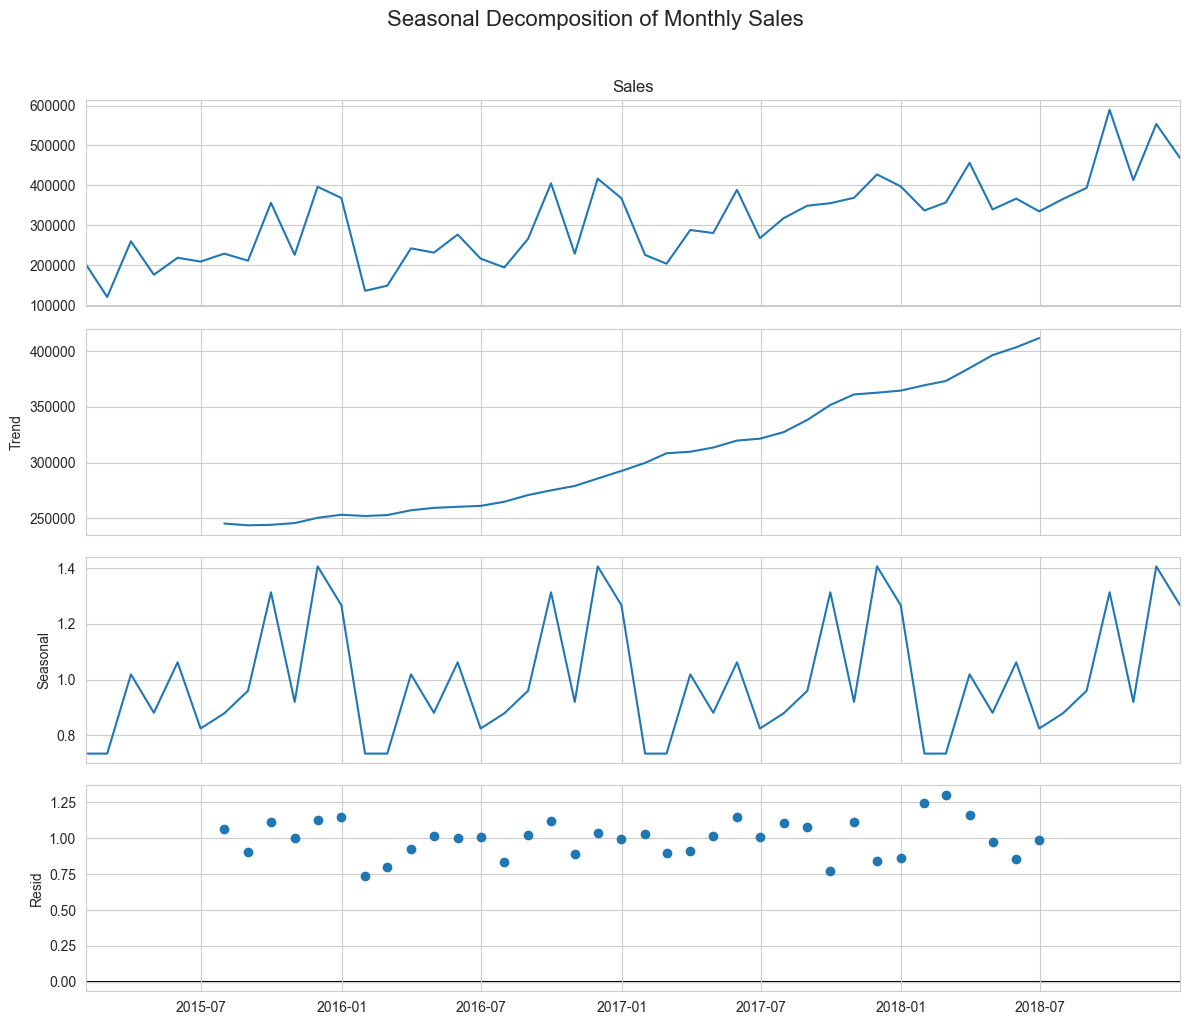

In [33]:
# Seasonal Decomposition

# Ensuring monthly_ts has a datetime index
monthly_ts.index = pd.to_datetime(monthly_ts.index)

# Performing multiplicative decomposition (best for sales data)
decomposition = seasonal_decompose(monthly_ts['Sales'], model='multiplicative', period=12)

# Plotting the decomposition
fig = decomposition.plot()
fig.set_size_inches(12, 10)
plt.suptitle("Seasonal Decomposition of Monthly Sales", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

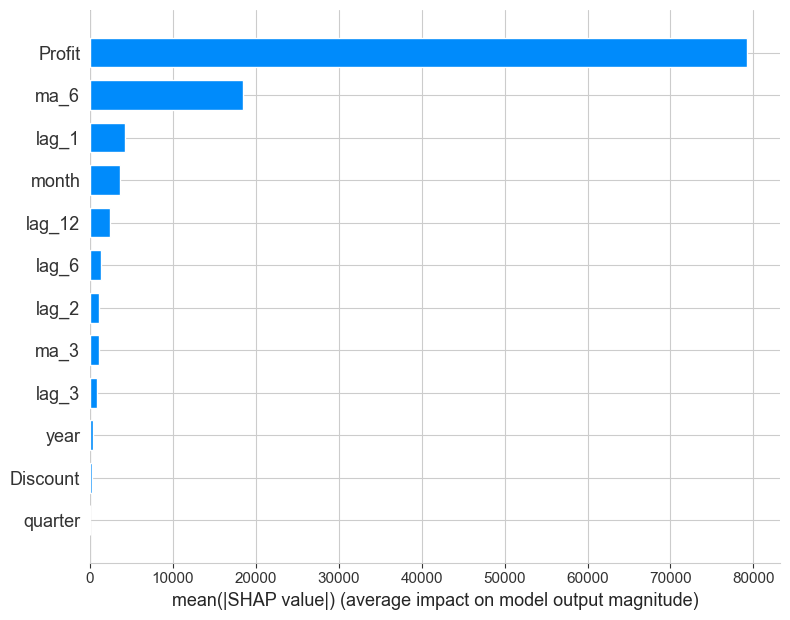

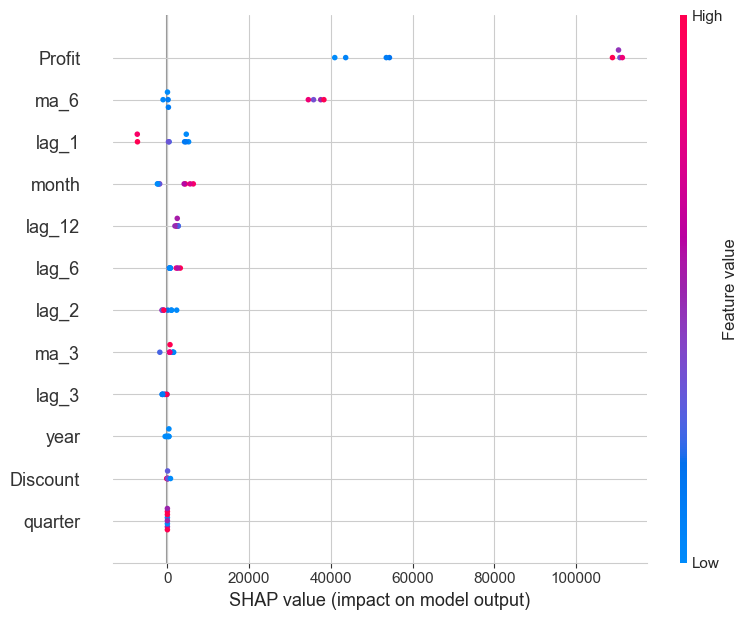

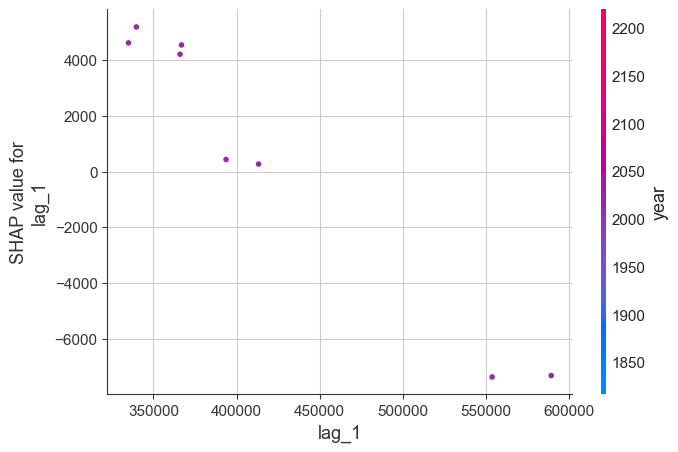

In [34]:
# SHAP Explainability 

# Initializing SHAP explainer for tree models (XGBoost)
# Initializing explainer using training data
explainer = shap.Explainer(best_xgb, X_train)  
# Applying SHAP on test data to observe real-world effect
shap_values = explainer(X_test)

# Global Feature Importance (Summary Plot)
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)

# Detailed Beeswarm Plot (shows push of features on predictions)
shap.summary_plot(shap_values, X_test, show=True)

# Feature Dependence Plot 
if 'lag_1' in X_test.columns:
    shap.dependence_plot('lag_1', shap_values.values, X_test)

In [35]:
# clustering       (new)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Check if Customer ID exists
if 'Customer ID' in df.columns:
    
    # Aggregate customer metrics
    customer_features = df.groupby('Customer ID').agg({
        'Sales': 'sum',
        'Profit': 'sum',
        'Order Date': 'count',
        'Discount': 'mean'
    }).rename(columns={'Order Date': 'Purchase_Frequency'})
    
    # Standardize
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(customer_features)
    
    # K-Means
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    customer_features['Cluster'] = kmeans.fit_predict(scaled_features)
    
    # Visualize
    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(
        customer_features['Sales'], 
        customer_features['Purchase_Frequency'],
        c=customer_features['Cluster'], 
        cmap='viridis', 
        alpha=0.6,
        s=100
    )
    plt.xlabel('Total Sales (₹)')
    plt.ylabel('Purchase Frequency')
    plt.title('Customer Segmentation')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Cluster statistics
    print("\n📊 Cluster Characteristics:")
    cluster_summary = customer_features.groupby('Cluster').agg({
        'Sales': 'mean',
        'Profit': 'mean',
        'Purchase_Frequency': 'mean',
        'Discount': 'mean'
    }).round(2)
    
    display(cluster_summary)
    
    # Name clusters
    cluster_names = {
        0: "💎 VIP Customers",
        1: "🌟 Loyal Customers", 
        2: "🎯 Potential Customers",
        3: "⚠️ At-Risk Customers"
    }
    
    for cluster_id, name in cluster_names.items():
        count = (customer_features['Cluster'] == cluster_id).sum()
        print(f"\n{name}: {count} customers")

else:
    print("⚠️ Customer ID column not found. Skipping segmentation.")

⚠️ Customer ID column not found. Skipping segmentation.


In [36]:
# Saving Linear Regression
joblib.dump(lr_model, MODELS_DIR / "linear_regression.pkl")

# Saving Random Forest
joblib.dump(best_rf, MODELS_DIR / "random_forest.pkl")

# Saving XGBoost
joblib.dump(best_xgb, MODELS_DIR / "xgboost.pkl")

# Saving Prophet model
joblib.dump(prophet_model, MODELS_DIR / "prophet_model.pkl")

print("All models saved successfully in", MODELS_DIR.resolve())

All models saved successfully in C:\Users\DELL\Desktop\MY PROJECTS\Smart Retail\models


In [37]:
# joblib.dump(scaler, MODELS_DIR / "scaler.pkl")  # saving clustering (new)

In [38]:
# Last date in historical data
last_date = monthly_agg['ds'].max()

# Generating next 6 months
future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=6, freq='MS')
future_df = pd.DataFrame({'ds': future_dates})

# Adding time-based features
future_df['year'] = future_df['ds'].dt.year
future_df['month'] = future_df['ds'].dt.month
future_df['quarter'] = future_df['ds'].dt.quarter

# Using historical averages for Profit and Discount
future_df['Profit'] = monthly_agg['Profit'].mean()
future_df['Discount'] = monthly_agg['Discount'].mean()

In [39]:
# Copying historical data to seed lag calculations
future_features = monthly_agg[['ds','y','year','month','quarter','Profit','Discount']].copy()

# Iterating through each future date
for date in future_df['ds']:
    
    # Creating new row with static features
    new_row = {
        'ds': date,
        'year': date.year,
        'month': date.month,
        'quarter': date.quarter,
        'Profit': monthly_agg['Profit'].mean(),
        'Discount': monthly_agg['Discount'].mean(),
        'y': np.nan  # placeholder for prediction
    }
    
    # Appending to future_features
    future_features = pd.concat([future_features, pd.DataFrame([new_row])], ignore_index=True)
    
    # Computing lag features using last known 'y' values
    future_features.loc[future_features.index[-1], 'lag_1'] = future_features['y'].iloc[-2]
    future_features.loc[future_features.index[-1], 'lag_2'] = future_features['y'].iloc[-3]
    future_features.loc[future_features.index[-1], 'lag_3'] = future_features['y'].iloc[-4]
    future_features.loc[future_features.index[-1], 'lag_6'] = future_features['y'].iloc[-7]
    future_features.loc[future_features.index[-1], 'lag_12'] = future_features['y'].iloc[-13]
    
    # Computing rolling features
    future_features.loc[future_features.index[-1], 'ma_3'] = future_features['y'].iloc[-4:-1].mean()
    future_features.loc[future_features.index[-1], 'ma_6'] = future_features['y'].iloc[-7:-1].mean()
    
    # Preparing feature vector for ML models
    feature_cols = ['year','month','quarter','lag_1','lag_2','lag_3','lag_6','lag_12','ma_3','ma_6','Profit','Discount']
    X_new = future_features[feature_cols].iloc[-1:].ffill()  #changed here
    
    # Predicting using ML models
    xgb_pred = best_xgb.predict(X_new)[0]
    rf_pred = best_rf.predict(X_new)[0]
    lr_pred = lr_model.predict(X_new)[0]
    
    future_features.loc[future_features.index[-1], 'y'] = np.mean([xgb_pred, rf_pred, lr_pred])

# Extracting future predictions
future_preds = future_features[future_features['ds'].isin(future_df['ds'])][['ds','y']].reset_index(drop=True)
display(future_preds)


# Prophet predictions
prophet_future_df = future_df[['ds']].copy()
prophet_forecast = prophet_model.predict(prophet_future_df)
prophet_future_preds = prophet_forecast[['ds','yhat']].copy()
display(prophet_future_preds)

,ds,y
0,2019-01-01,378061.288609
1,2019-02-01,427086.351109
2,2019-03-01,399284.996942
3,2019-04-01,367992.600443
4,2019-05-01,385026.036937
5,2019-06-01,376886.381717


,ds,yhat
0,2019-01-01,21020.997449
1,2019-02-01,13934.507783
2,2019-03-01,11850.028370
3,2019-04-01,13023.220905
4,2019-05-01,16144.343189
5,2019-06-01,16554.493595


In [40]:
# Saving predictions to CSV
future_preds.to_csv(DATA_DIR / "future_ml_predictions.csv", index=False)
prophet_future_preds.to_csv(DATA_DIR / "future_prophet_predictions.csv", index=False)

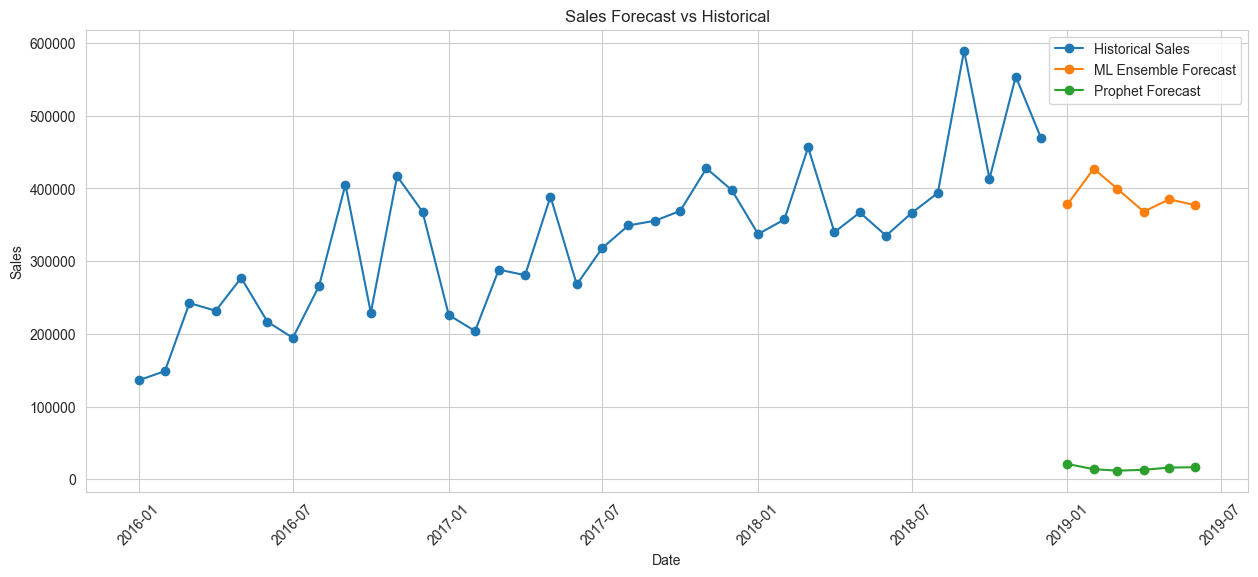

In [41]:
# Plotting historical vs predicted
plt.figure(figsize=(15,6))
plt.plot(monthly_agg['ds'], monthly_agg['y'], label='Historical Sales', marker='o')
plt.plot(future_preds['ds'], future_preds['y'], label='ML Ensemble Forecast', marker='o')
plt.plot(prophet_future_preds['ds'], prophet_future_preds['yhat'], label='Prophet Forecast', marker='o')
plt.title('Sales Forecast vs Historical')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()